<h1> Programming for Physics <br> Lecture 13: Plots and Animations </h1>
<a target="_blank" href="https://colab.research.google.com/github/slxuphys/tamu_phys_150/blob/master/2026/lecture-13-matplotlib.ipynb">
  <img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/>
</a>
   

## Matplotlib
Matplotlib is a package for scientific plotting in Python.
   > "A picture is worth a thousand words" 


<img src="https://towardsdatascience.com/wp-content/uploads/2020/10/1OAFEIg9w1XHyZk0xBud14A.png" style="width:800px;" width="800">

We can also create animations with Matplotlib!

## Figures and plot objects

A figure contains many objects. They can all be updated in place. 

Steps to make a figure:

0. import the packages/modules
1. prepare data
2. plot
3. add labels
4. add legend
5. fine tuning


![figure](https://tacaswell.github.io/matplotlib/_images/anatomy.png)

### Example: Sine and cosine

Plot sin(x) and cos(x) function for 0< x < 2 $\pi$  

In [19]:
import matplotlib.pyplot as plt
import numpy as np

In [20]:
x_data = np.linspace(0,2*np.pi,100) #one hundred data point
sin_data = np.sin(x_data)
cos_data = np.cos(x_data)

#### basic plotting

Text(0, 0.5, 'f(x)')

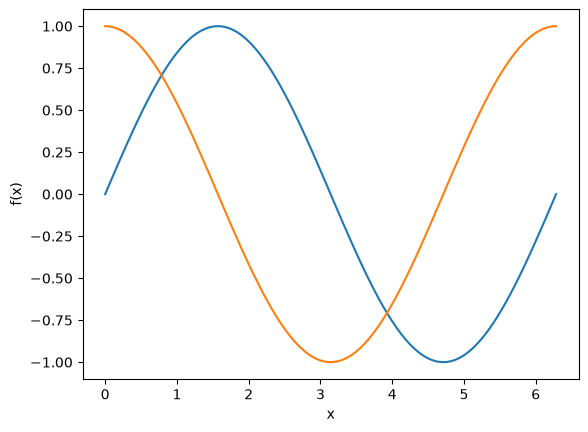

In [37]:
plt.plot(x_data, sin_data)
plt.plot(x_data, cos_data)
plt.xlabel("x")
plt.ylabel("f(x)")

#### Polished Plotting

(np.float64(-0.3141592653589793),
 np.float64(6.5973445725385655),
 np.float64(-1.099867834057569),
 np.float64(1.0999937063836938))

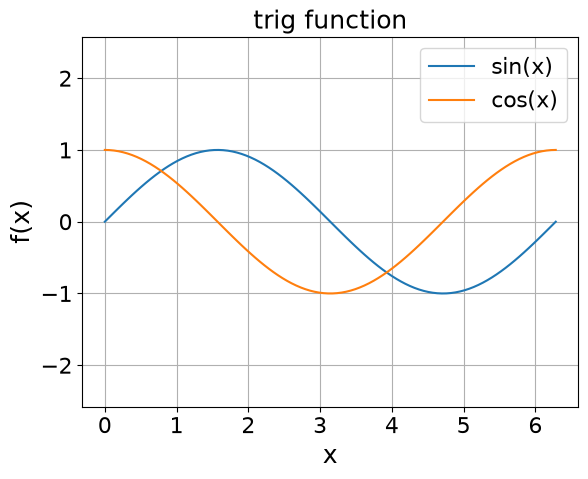

In [46]:
sin_line, = plt.plot(x_data, sin_data)
cos_line, = plt.plot(x_data, cos_data)
xlabel = plt.xlabel('x',fontsize=18) #set xlabel and return the xlabel object
ylabel = plt.ylabel('f(x)', fontsize=18) #set ylabel and return the ylabel object
title = plt.title('trig function',fontsize=18) #set title and return the title object
legend = plt.legend(('sin(x)','cos(x)'),fontsize=16) #set legend and return the legend object
plt.xticks(fontsize=16)
plt.yticks(fontsize=16)
plt.grid(True)
fig = plt.gcf() #get current figure object
ax = plt.gca() #get current axes object
ax.axis('equal') #set the scale for both axis to be same

__Each component in the figure is an object belonging to a specific class__

Figure -> Axes -> {Axis, Line2D, Text, Legend, ...}


In [41]:
print(type(fig))
print(type(ax))
print(type(xlabel))
print(type(legend))
print(type(sin_line))

<class 'matplotlib.figure.Figure'>
<class 'matplotlib.axes._axes.Axes'>
<class 'matplotlib.text.Text'>
<class 'matplotlib.legend.Legend'>
<class 'matplotlib.lines.Line2D'>


__These objects can be updated in place__

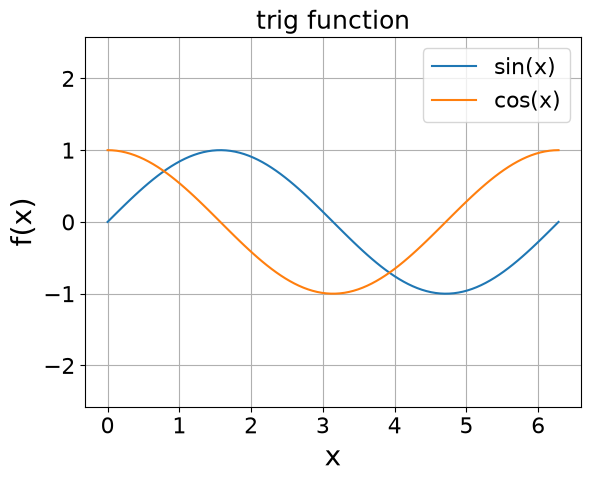

In [42]:
xlabel.set_fontsize(20)
ylabel.set_fontsize(20)
fig

### Saving a figure

`Figure` object has a `savefig` method to save the figure to a file.

Example:
```python
fig.savefig("my_figure.png")
```

In [34]:
fig.savefig("trig.png")

### Axes objects
An Axes object represents a plotting area within a figure. We can get the Axes objects from the figure using `fig.axes`.
`fig.axes` returns a list of all Axes objects in the figure.

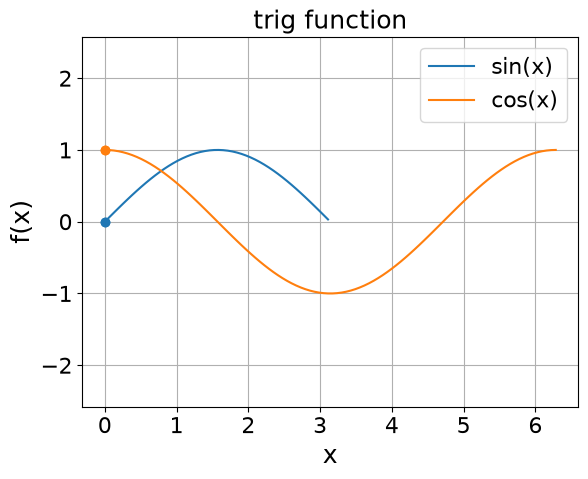

In [51]:
ax = fig.axes[0]

## plot points for sin and cos
sin_ball, = ax.plot(0, 0, 'o', color='tab:blue')
cos_ball, = ax.plot(0, 1, 'o', color='tab:orange') 

fig

### Line objects

Plotting curves using the `plot` method of an Axes object creates Line2D objects.

Then we can change the curve by using `set_data` method of lines. The `set_data` method takes two arguments: the new x-data and the new y-data.

We can also get the line objects using the `get_lines()` method of an Axes object. It returns a __list__ of Line2D objects.




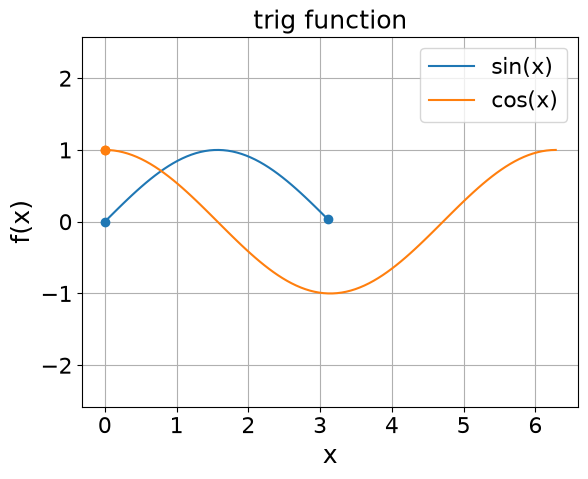

In [56]:
sin_line.set_data(x_data[0:50], sin_data[0:50])
sin_ball.set_data([x_data[49]], [sin_data[49]])
fig

__Take Home Message: Everything on figure can be modified IN PLACE__

You don't have to remember how. Just google it.


---

## Animation

The key idea: update the figure for each frame and show the figure frame by frame

Write a function to update the figure based on the frame index

In [59]:
def draw_frame(frame_index):
    sin_line.set_data(x_data[0:frame_index+1], sin_data[0:frame_index+1])
    cos_line.set_data(x_data[0:frame_index+1], cos_data[0:frame_index+1])
    sin_ball.set_data([x_data[frame_index]], [sin_data[frame_index]])
    cos_ball.set_data([x_data[frame_index]], [cos_data[frame_index]])


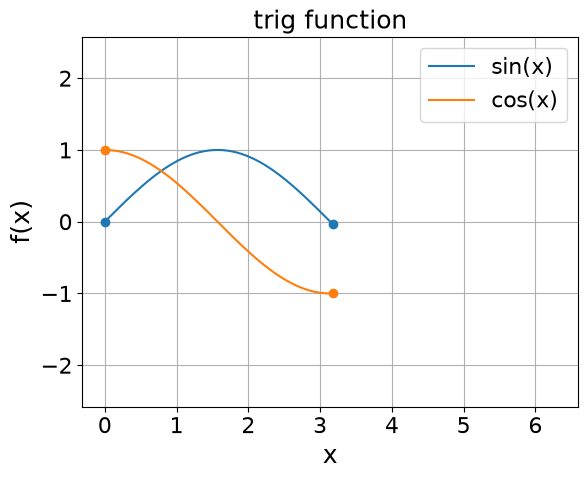

In [60]:
draw_frame(50)
fig

### Method I: Manual frame updates

Put the draw_frame() function in a loop and show the figure in each iteration

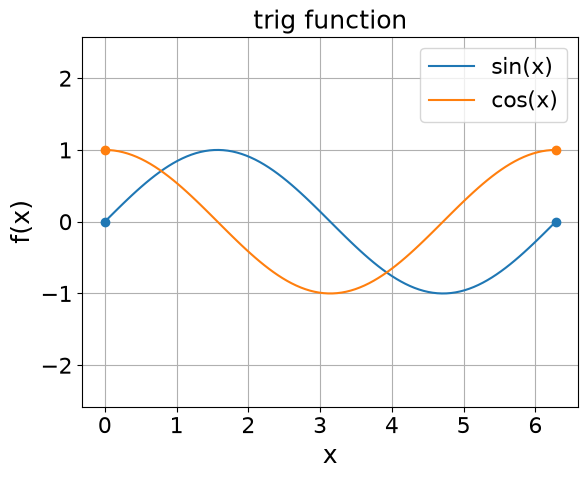

In [61]:
import IPython
import time
for i_frame in range(100):
    draw_frame(i_frame)
    IPython.display.display(fig) #show the fig after it is updated
    IPython.display.clear_output(wait=True) #clear the figure once a new figure is shown
    time.sleep(0.005) #wait for 0.01 sec between each iteration

### Method II: FuncAnimation (preferred)

Matplotlib has an animation module that does this for you

In [62]:
import matplotlib.animation as animation
anim=animation.FuncAnimation(fig, draw_frame, frames=100, interval=20) 
# the first argument is the figure object
# the second argument is the function updates the figure for each frame
# the third argument is the total number of frames
# the fourth interval is the time interval between two frames in milliseconds

In [31]:
anim

In [63]:
IPython.display.HTML(anim.to_jshtml())

## Physics example: Plotting harmonic motion

<img src='https://github.com/slxuphys/tamu_phys_150/blob/master/gallery/water_spring.png?raw=true' style='height:400px;background-color:white;' height=400>

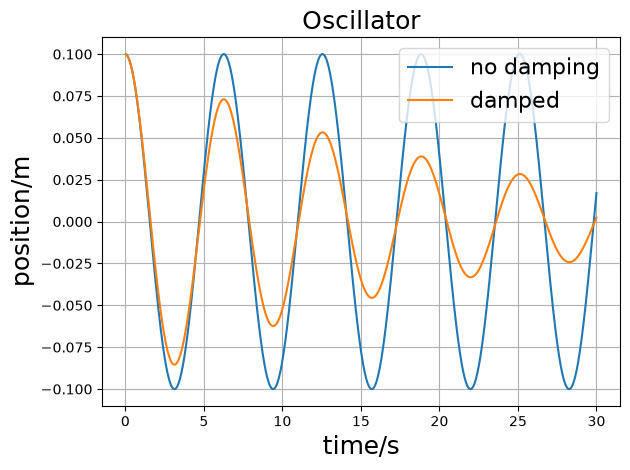

In [64]:
import physics as phy # check lecture 12 on module, and make sure the module file physics.py is in the same directory

ball1=phy.Ball(x=0.1)
phy.motion(t_max=30,num_step=1000,ball=ball1,f_a=lambda x,v:-x)
ball2=phy.Ball(x=0.1)
phy.motion(t_max=30,num_step=1000,ball=ball2,f_a=lambda x,v:-x-0.1*v)
plt.plot(ball1.time_list, ball1.pos_list)
plt.plot(ball2.time_list, ball2.pos_list)
fig=plt.gcf()
ax=plt.gca()
plt.xlabel('time/s',fontsize=18)
plt.ylabel('position/m',fontsize=18)
plt.title('Oscillator',fontsize=18)
plt.legend(('no damping','damped'),fontsize=16)
plt.grid(True)
plt.tight_layout()


In [ ]:
fig.savefig('oscillator.png')

## Physics example: Animating an orbit

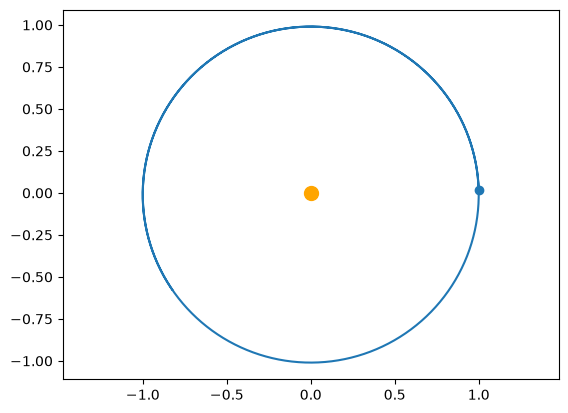

In [68]:
import physics as phy
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.animation as animation
import IPython
ball = phy.Ball(x=(1, 0), v=(0, 1))
phy.motion(t_max=10, num_step=500, ball=ball, f_a=lambda x, v: -np.array(x)/np.linalg.norm(x)**3)
ball.pos_list = np.array(ball.pos_list)
x_data, y_data = ball.pos_list[:, 0], ball.pos_list[:, 1]
trajectory, = plt.plot(x_data, y_data) # plot the trajectory of the ball and return the line object
plt.axis('equal')
fig = plt.gcf()
ax = plt.gca()
sun, = plt.plot(0, 0, 'o', color='orange', markersize=10) # draw the central mass
earth, = plt.plot(x_data[0], y_data[0], 'o', color='tab:blue') # draw the orbiting mass


In [69]:
def draw_frame(frame_index):
    index = frame_index*5 # speed up the animation by skipping frames
    if index >= len(x_data):
        index = len(x_data) - 1 # prevent index out of range
    earth.set_data([x_data[index]], [y_data[index]])
    trajectory.set_data(x_data[0:index], y_data[0:index])

In [70]:
anim=animation.FuncAnimation(fig, draw_frame, frames=100, interval=20)
IPython.display.HTML(anim.to_jshtml())